# Perfilado de datos — Spotify y Premios Grammy

**ETL Workshop-2 · Sección 6.3 del enunciado**

El perfilado es **recolección de evidencia**: describe los datos tal como llegan y soporta las
decisiones de calidad, transformación e integración. **Este notebook no modifica ningún dato**:
lee los archivos originales y solo guarda tablas de evidencia en `docs/evidence/profiling/`.

| Categoría de evidencia (enunciado) | Sección |
| --- | --- |
| Estructura | 1 |
| Completitud | 2 |
| Unicidad y duplicación | 3 |
| Contenido categórico | 4 |
| Contenido numérico | 5 |
| Contenido temporal | 6 |
| Consistencia entre fuentes | 7 |
| Tabla de riesgos | 8 |

**Requerimientos analíticos:** ver `docs/requirements.md` (R1–R4).

> **Fuente de Grammy:** se perfila el CSV original. La tabla `grammy_source.grammy_awards` en
> PostgreSQL es una copia exacta (conciliación 4,810 = 4,810, evidencia E02), por lo que la
> evidencia aplica a ambas.

In [1]:
from pathlib import Path
import re
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Funciona tanto si se ejecuta desde notebooks/ como desde la raíz del proyecto
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
EVID = ROOT / "docs" / "evidence" / "profiling"
EVID.mkdir(parents=True, exist_ok=True)

# Solo la celda vacia cuenta como nulo: textos como "N/A" o "None" se conservan para
# poder detectarlos como nulos disfrazados (ver seccion 4)
spotify = pd.read_csv(RAW / "spotify_dataset.csv", keep_default_na=False, na_values=[""])
grammy = pd.read_csv(RAW / "the_grammy_awards.csv", keep_default_na=False, na_values=[""])

def guardar(df, nombre):
    """Guarda una tabla de evidencia en CSV y la devuelve para mostrarla."""
    df.to_csv(EVID / f"{nombre}.csv", index=True)
    return df

## 1. Estructura

In [2]:
estructura = pd.DataFrame({
    "dataset": ["spotify_dataset.csv", "the_grammy_awards.csv"],
    "filas": [len(spotify), len(grammy)],
    "columnas": [spotify.shape[1], grammy.shape[1]],
}).set_index("dataset")
guardar(estructura, "01_estructura")

,filas,columnas
dataset,,
spotify_dataset.csv,114000,21
the_grammy_awards.csv,4810,10


In [3]:
print("SPOTIFY")
print(spotify.dtypes.to_string())
print("\nGRAMMY")
print(grammy.dtypes.to_string())

SPOTIFY
Unnamed: 0            int64
track_id             object
artists              object
album_name           object
track_name           object
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre          object

GRAMMY
year             int64
title           object
published_at    object
updated_at      object
category        object
nominee         object
artist          object
workers         object
img             object
winner            bool


**Hallazgos de estructura**

- Spotify tiene una **primera columna sin nombre** (`Unnamed: 0`): es un índice de exportación
  de pandas (0, 1, 2…), sin valor analítico.
- En Grammy, `published_at` y `updated_at` llegan como texto con zona horaria (`-07:00`).
  `winner` llega como booleano.

In [4]:
# ¿La columna sin nombre es solo un consecutivo 0..n-1?
idx = spotify.iloc[:, 0]
print("Nombre:", spotify.columns[0])
print("Es exactamente 0..n-1:", idx.equals(pd.Series(range(len(spotify)))))

Nombre: Unnamed: 0
Es exactamente 0..n-1: True


## 2. Completitud

In [5]:
def completitud(df):
    t = pd.DataFrame({"nulos": df.isna().sum(), "pct_nulos": (df.isna().mean() * 100).round(2)})
    return t[t["nulos"] > 0].sort_values("nulos", ascending=False)

print("SPOTIFY"); display(guardar(completitud(spotify), "02_completitud_spotify"))
print("GRAMMY");  display(guardar(completitud(grammy), "02_completitud_grammy"))

SPOTIFY


,nulos,pct_nulos
artists,1,0.0
album_name,1,0.0
track_name,1,0.0


GRAMMY


,nulos,pct_nulos
workers,2190,45.53
artist,1840,38.25
img,1367,28.42
nominee,6,0.12


In [6]:
# Spotify: la fila con nulos
spotify[spotify["artists"].isna()]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [7]:
# Grammy: ¿en qué categorías falta el artista?
falta_artista = (grammy[grammy["artist"].isna()]["category"]
                 .value_counts().head(10).rename("filas_sin_artist"))
guardar(falta_artista.to_frame(), "02_grammy_categorias_sin_artist")

,filas_sin_artist
category,
Song Of The Year,70
Best Opera Recording,64
Best Album Notes,63
Best Instrumental Composition,55
Best Country Song,55
Best New Artist,50
Best Historical Album,44
Best Chamber Music Performance,43
Best Instrumental Arrangement,39


In [8]:
# En 'Best New Artist' el artista viene en 'nominee' y no en 'artist'
grammy[grammy["category"].str.contains("New Artist", case=False)][["year", "category", "nominee", "artist"]].head(8)

,year,category,nominee,artist
24,2019,Best New Artist,Billie Eilish,NaN
25,2019,Best New Artist,Black Pumas,NaN
26,2019,Best New Artist,Lil Nas X,NaN
27,2019,Best New Artist,Lizzo,NaN
28,2019,Best New Artist,Maggie Rogers,NaN
29,2019,Best New Artist,ROSALÍA,NaN
30,2019,Best New Artist,Tank And The Bangas,NaN
31,2019,Best New Artist,Yola,NaN


**Interpretación en contexto**

- Spotify: **1 sola fila** (de 114,000) sin `artists`, `album_name` ni `track_name`. Es inutilizable
  para R1–R4 porque no se puede asociar a ningún artista.
- Grammy: `artist` falta en **38 %** de las filas. No es un error aleatorio: ocurre en categorías
  donde se premia una obra, una composición o una persona (*Song Of The Year*, *Best Opera
  Recording*, *Best Album Notes*…). En *Best New Artist*, el nombre del artista está en `nominee`.
  Esto afecta directamente la cobertura de la integración (R1–R4).
- `workers` e `img` tienen nulos, pero **no son requeridos** por ningún requerimiento.

## 3. Unicidad y duplicación

In [9]:
sin_indice = spotify.drop(columns=spotify.columns[0])
unicidad = pd.DataFrame({
    "medida": [
        "Filas Spotify",
        "track_id distintos",
        "Filas con track_id repetido (sobran)",
        "Duplicados exactos (todas las columnas excepto el índice)",
        "track_id presentes en más de un género",
        "track_id con popularidad distinta entre sus filas",
        "Filas Grammy",
        "Duplicados exactos Grammy",
        "Duplicados por (year, category, nominee, artist)",
    ],
    "valor": [
        len(spotify),
        spotify["track_id"].nunique(),
        spotify["track_id"].duplicated().sum(),
        sin_indice.duplicated().sum(),
        (spotify.groupby("track_id")["track_genre"].nunique() > 1).sum(),
        (spotify.groupby("track_id")["popularity"].nunique() > 1).sum(),
        len(grammy),
        grammy.duplicated().sum(),
        grammy.duplicated(["year", "category", "nominee", "artist"]).sum(),
    ],
}).set_index("medida")
guardar(unicidad, "03_unicidad")

,valor
medida,
Filas Spotify,114000
track_id distintos,89741
Filas con track_id repetido (sobran),24259
Duplicados exactos (todas las columnas excepto el índice),450
track_id presentes en más de un género,16299
track_id con popularidad distinta entre sus filas,720
Filas Grammy,4810
Duplicados exactos Grammy,0
"Duplicados por (year, category, nominee, artist)",0


In [10]:
# Ejemplo: una misma canción repetida en varios géneros
ejemplo = spotify["track_id"].value_counts().index[0]
spotify[spotify["track_id"] == ejemplo][["track_id", "artists", "track_name", "popularity", "track_genre"]]

,track_id,artists,track_name,popularity,track_genre
8315,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,blues
19759,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,country
34728,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,folk
62226,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,j-pop
63087,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,j-rock
82064,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,power-pop
84129,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,psych-rock
99727,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,singer-songwriter
102732,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,songwriter


**Interpretación — ¿los repetidos son esperados en la granularidad de la fuente?**

- La granularidad real de Spotify es **canción × género**, no canción. Por eso `track_id` no es una
  llave única: 16,641 canciones aparecen en varios géneros. Esa repetición **es esperada**.
- En cambio, los **450 duplicados exactos** (misma canción, mismo género, mismos valores) **no son
  esperados**: inflarían conteos y promedios de R1–R3.
- Hay canciones con **popularidad distinta** entre sus filas: la misma canción no debería tener dos
  popularidades. Es un riesgo de consistencia para R1 y R4.
- Grammy no tiene duplicados por la combinación (year, category, nominee, artist).

## 4. Contenido categórico

In [11]:
print("Valores de 'winner' en Grammy:")
display(guardar(grammy["winner"].value_counts(dropna=False).to_frame("filas"), "04_grammy_winner"))

Valores de 'winner' en Grammy:


,filas
winner,
True,4810


In [12]:
# Prueba de sentido común: en una categoría y un año hay UN ganador (a veces un empate de 2)
por_categoria = grammy.groupby(["year", "category"]).size().rename("registros").reset_index()
por_categoria["lote"] = (por_categoria["year"] == 2019).map({True: "2019", False: "1958-2018"})
resumen_winner = por_categoria.groupby("lote")["registros"].agg(
    combinaciones="size", promedio="mean", maximo="max",
    con_mas_de_1=lambda s: (s > 1).sum(), con_mas_de_2=lambda s: (s > 2).sum(),
).round(3)
guardar(resumen_winner, "04_grammy_registros_por_categoria")

,combinaciones,promedio,maximo,con_mas_de_1,con_mas_de_2
lote,,,,,
1958-2018,4346,1.007,2,31,0
2019,84,5.155,8,84,84


In [13]:
# Registros por año: 2019 rompe el patrón
grammy.groupby("year").size().tail(6)

year
2014     83
2015     84
2016     85
2017     86
2018     86
2019    433
dtype: int64

In [14]:
grammy[(grammy["year"] == 2019) & (grammy["category"] == "Record Of The Year")][["nominee", "artist", "winner"]]

,nominee,artist,winner
0,Bad Guy,Billie Eilish,True
1,"Hey, Ma",Bon Iver,True
2,7 rings,Ariana Grande,True
3,Hard Place,H.E.R.,True
4,Talk,Khalid,True
5,Old Town Road,Lil Nas X Featuring Billy Ray Cyrus,True
6,Truth Hurts,Lizzo,True
7,Sunflower,Post Malone & Swae Lee,True


**Hallazgo crítico (lote 2019).** De 1958 a 2018 el dataset tiene en promedio **1 registro por
(año, categoría)** y nunca más de 2 (empates reales): **representa a los ganadores**. En **2019**
hay 433 registros (frente a 86 en 2018) y 84 categorías con 5 a 8 registros, **todos con
`winner = True`**. En *Record Of The Year 2019* solo ganó "Bad Guy", pero las 8 nominadas figuran
como ganadoras. **En 2019 la columna `winner` no distingue ganadores de nominados** → ese lote se
excluye de los KPIs de ganadores (ver `docs/requirements.md`). No se corrige adivinando el ganador.

In [15]:
# Variación de mayúsculas en las categorías
cat = grammy["category"]
variantes = (cat.groupby(cat.str.lower()).nunique().loc[lambda s: s > 1])
print("Categorías distintas:", cat.nunique(), "| distintas ignorando mayúsculas:", cat.str.lower().nunique())
ejemplos = grammy[cat.str.lower().isin(variantes.index)][["category"]].drop_duplicates().sort_values("category")
guardar(ejemplos.head(16).set_index("category"), "04_grammy_categorias_variantes")

Categorías distintas: 638 | distintas ignorando mayúsculas: 630


""
category
Best Classical Performance - Instrumental Soloist OR Soloists (With Orchestra)
Best Classical Performance - Instrumental Soloist Or Soloists (With Orchestra)
Best Instrumental Soloist Performance (Without Orchestra)
Best Instrumental Soloist Performance (without Orchestra)
Best Instrumental Soloist(s) Performance (With Orchestra)
Best Instrumental Soloist(s) Performance (with Orchestra)
Best Small Ensemble Performance (With Or Without Conductor)
Best Small Ensemble Performance (with or without Conductor)
"Best Southern, Country, Or Bluegrass Gospel Album"


In [16]:
# Doble espacio en 'title'
print("Filas con doble espacio en title:", grammy["title"].str.contains("  ").sum(), "de", len(grammy))
grammy["title"].unique()[:3]

Filas con doble espacio en title: 4810 de 4810


array(['62nd Annual GRAMMY Awards  (2019)',
       '61st Annual GRAMMY Awards  (2018)',
       '60th Annual GRAMMY Awards  (2017)'], dtype=object)

In [17]:
# Artistas múltiples en una sola celda
multi = pd.DataFrame({
    "patron": ["Spotify: ';' en artists", "Grammy: ' & ' en artist", "Grammy: ' Featuring ' en artist",
               "Grammy: ', ' en artist", "Grammy: '(' en artist"],
    "filas": [
        spotify["artists"].str.contains(";", na=False).sum(),
        grammy["artist"].str.contains(" & ", na=False).sum(),
        grammy["artist"].str.contains(" Featuring ", case=False, na=False).sum(),
        grammy["artist"].str.contains(", ", na=False).sum(),
        grammy["artist"].str.contains(r"\(", na=False).sum(),
    ],
}).set_index("patron")
guardar(multi, "04_artistas_multiples")

,filas
patron,
Spotify: ';' en artists,30075
Grammy: ' & ' en artist,411
Grammy: ' Featuring ' en artist,86
"Grammy: ', ' en artist",124
Grammy: '(' en artist,153


In [18]:
# Dominio de géneros de Spotify
generos = spotify["track_genre"].value_counts()
print("Géneros distintos:", generos.size, "| filas por género: min", generos.min(), "max", generos.max())
generos.head(10)

Géneros distintos: 114 | filas por género: min 1000 max 1000


track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64

In [19]:
# Nulos disfrazados: textos que ocupan el lugar de un artista sin identificar a nadie
creditos = spotify["artists"].dropna().str.split(";").explode().str.strip()
marcadores = ["N/A", "NA", "None", "null", "Unknown", "Various Artists"]
disfrazados = creditos[creditos.isin(marcadores)].value_counts().rename("creditos")
display(guardar(disfrazados.to_frame(), "04_spotify_artistas_marcador"))
print("Spotify artists con espacios sobrantes:", (spotify["artists"].dropna() != spotify["artists"].dropna().str.strip()).sum())
print("Grammy artist con espacios sobrantes:", (grammy["artist"].dropna() != grammy["artist"].dropna().str.strip()).sum())

,creditos
artists,
N/A,2
Unknown,1
Various Artists,1


Spotify artists con espacios sobrantes: 8
Grammy artist con espacios sobrantes: 0


## 5. Contenido numérico

In [20]:
numericas = ["popularity", "duration_ms", "danceability", "energy", "speechiness", "acousticness",
             "instrumentalness", "liveness", "valence", "loudness", "tempo", "key", "mode", "time_signature"]
guardar(spotify[numericas].describe().T.round(3), "05_spotify_numericas")

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996
instrumentalness,114000.0,0.156,0.310,0.000,0.000,0.000,0.049,1.000
liveness,114000.0,0.214,0.190,0.000,0.098,0.132,0.273,1.000
valence,114000.0,0.474,0.259,0.000,0.260,0.464,0.683,0.995
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532


In [21]:
rango_0_1 = ["danceability", "energy", "speechiness", "acousticness", "instrumentalness", "liveness", "valence"]
sospechosos = pd.DataFrame({
    "condicion": [
        "Features de audio fuera de [0, 1]",
        "duration_ms = 0",
        "duration_ms > 30 minutos",
        "tempo = 0",
        "time_signature = 0",
        "loudness > 0 dB",
        "popularity = 0",
        "popularity fuera de [0, 100]",
    ],
    "filas": [
        int(((spotify[rango_0_1] < 0) | (spotify[rango_0_1] > 1)).any(axis=1).sum()),
        int((spotify["duration_ms"] == 0).sum()),
        int((spotify["duration_ms"] > 30 * 60 * 1000).sum()),
        int((spotify["tempo"] == 0).sum()),
        int((spotify["time_signature"] == 0).sum()),
        int((spotify["loudness"] > 0).sum()),
        int((spotify["popularity"] == 0).sum()),
        int(((spotify["popularity"] < 0) | (spotify["popularity"] > 100)).sum()),
    ],
}).set_index("condicion")
sospechosos["pct"] = (sospechosos["filas"] / len(spotify) * 100).round(2)
guardar(sospechosos, "05_spotify_valores_sospechosos")

,filas,pct
condicion,,
"Features de audio fuera de [0, 1]",0,0.00
duration_ms = 0,1,0.00
duration_ms > 30 minutos,36,0.03
tempo = 0,157,0.14
time_signature = 0,163,0.14
loudness > 0 dB,90,0.08
popularity = 0,16020,14.05
"popularity fuera de [0, 100]",0,0.00


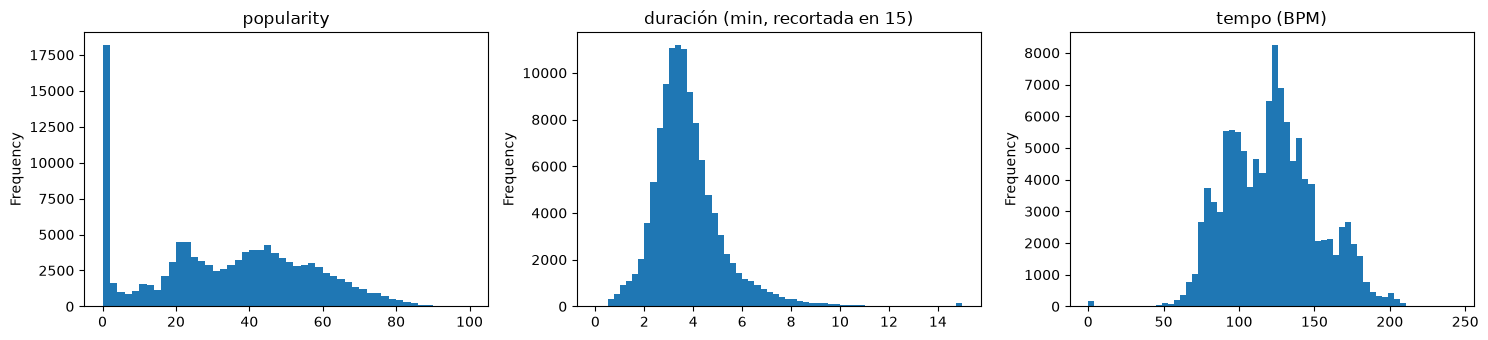

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
spotify["popularity"].plot.hist(bins=50, ax=axes[0], title="popularity")
spotify["duration_ms"].div(60000).clip(upper=15).plot.hist(bins=60, ax=axes[1], title="duración (min, recortada en 15)")
spotify["tempo"].plot.hist(bins=60, ax=axes[2], title="tempo (BPM)")
plt.tight_layout()
plt.savefig(EVID / "05_distribuciones_spotify.png", dpi=110)
plt.show()

**Interpretación**

- Las características de audio **sí respetan el rango [0, 1]**: es un contrato de la fuente que
  conviene vigilar con una regla (R3), aunque hoy se cumpla.
- `popularity = 0` en **14 %** de las filas: es un valor posible (canción poco escuchada), no
  necesariamente un error, pero pesa mucho en los promedios de R1 y R4. Se monitorea, no se borra.
- `tempo = 0`, `time_signature = 0` y `duration_ms = 0` son físicamente imposibles para una
  canción: son pocos casos, pero son valores inválidos.

## 6. Contenido temporal

In [23]:
pub = pd.to_datetime(grammy["published_at"], utc=True, errors="coerce")
upd = pd.to_datetime(grammy["updated_at"], utc=True, errors="coerce")
anio_titulo = grammy["title"].str.extract(r"\((\d{4})\)")[0].astype("Int64")
temporal = pd.DataFrame({
    "medida": [
        "year mínimo", "year máximo", "años distintos",
        "años faltantes en el rango",
        "published_at no parseables", "updated_at no parseables",
        "published_at mínimo", "published_at máximo",
        "year distinto del año en title",
    ],
    "valor": [
        grammy["year"].min(), grammy["year"].max(), grammy["year"].nunique(),
        len(set(range(grammy["year"].min(), grammy["year"].max() + 1)) - set(grammy["year"])),
        int(pub.isna().sum()), int(upd.isna().sum()),
        str(pub.min()), str(pub.max()),
        int((grammy["year"] != anio_titulo).sum()),
    ],
}).set_index("medida")
guardar(temporal, "06_grammy_temporal")

,valor
medida,
year mínimo,1958
year máximo,2019
años distintos,62
años faltantes en el rango,0
published_at no parseables,0
updated_at no parseables,0
published_at mínimo,2017-11-28 08:03:45+00:00
published_at máximo,2020-05-19 12:10:28+00:00
year distinto del año en title,0


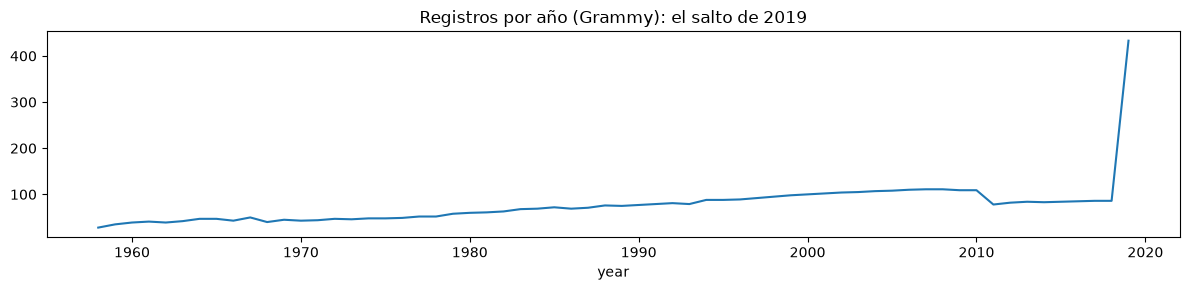

In [24]:
grammy.groupby("year").size().plot(figsize=(12, 3), title="Registros por año (Grammy): el salto de 2019")
plt.tight_layout(); plt.savefig(EVID / "06_nominaciones_por_anio.png", dpi=110); plt.show()

**Interpretación**

- `year` cubre **1958–2019 sin años faltantes** y coincide con el año del `title` en todas las filas.
- `published_at`/`updated_at` son fechas de **publicación en la web** (2017–2020), no de la
  ceremonia. No sirven para R4: la dimensión temporal se toma de `year`.
- Spotify **no tiene ninguna columna temporal**: el tiempo del análisis solo lo aporta Grammy.

## 7. Consistencia entre fuentes

La única forma de cruzar las fuentes es el **nombre del artista**. Se mide cuánto cruce se logra
con distintos niveles de normalización. *Esta normalización es solo para medir; la regla definitiva
se aplica en la fase de transformación.*

In [25]:
def normalizar(texto):
    """minúsculas, sin tildes, sin signos de puntuación y sin espacios repetidos."""
    if pd.isna(texto):
        return None
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    texto = re.sub(r"[^a-z0-9 ]", " ", texto.lower())
    return re.sub(r"\s+", " ", texto).strip() or None

# Spotify: cada canción puede tener varios artistas separados por ';'
artistas_spotify_raw = {a.strip() for fila in spotify["artists"].dropna() for a in fila.split(";")}
artistas_spotify_norm = {normalizar(a) for a in artistas_spotify_raw}

# Grammy: artista; en categorías de 'New Artist' se toma de nominee
es_new_artist = grammy["category"].str.contains("New Artist", case=False)
artista_grammy = grammy["artist"].where(~(es_new_artist & grammy["artist"].isna()), grammy["nominee"])

def artista_principal(texto):
    """Primer artista antes de ' Featuring ', ' & ', ' With ' o ', '."""
    if pd.isna(texto):
        return None
    return re.split(r" featuring | & | with |, ", str(texto), flags=re.IGNORECASE)[0]

escenarios = {
    "1. Texto exacto (sin normalizar)": (grammy["artist"], artistas_spotify_raw),
    "2. Normalizado": (grammy["artist"].map(normalizar), artistas_spotify_norm),
    "3. Normalizado + artista desde nominee en 'New Artist'": (artista_grammy.map(normalizar), artistas_spotify_norm),
    "4. Escenario 3 + solo artista principal": (artista_grammy.map(artista_principal).map(normalizar), artistas_spotify_norm),
}
filas = []
for nombre, (serie, universo) in escenarios.items():
    con_artista = serie.dropna()
    filas.append({
        "escenario": nombre,
        "filas_grammy_con_artista": len(con_artista),
        "filas_que_cruzan": int(con_artista.isin(universo).sum()),
        "artistas_distintos": con_artista.nunique(),
        "artistas_distintos_que_cruzan": con_artista[con_artista.isin(universo)].nunique(),
    })
cruce = pd.DataFrame(filas).set_index("escenario")
cruce["pct_filas_cruzan"] = (cruce["filas_que_cruzan"] / len(grammy) * 100).round(1)
guardar(cruce, "07_cruce_artistas")

,filas_grammy_con_artista,filas_que_cruzan,artistas_distintos,artistas_distintos_que_cruzan,pct_filas_cruzan
escenario,,,,,
1. Texto exacto (sin normalizar),2970,1276,1658,517,26.5
2. Normalizado,2970,1388,1644,538,28.9
3. Normalizado + artista desde nominee en 'New Artist',3035,1427,1668,550,29.7
4. Escenario 3 + solo artista principal,3035,1668,1422,610,34.7


In [26]:
# Ejemplos de artistas que NO cruzan aun normalizados (para entender por qué)
serie = artista_grammy.map(normalizar).dropna()
no_cruzan = artista_grammy[serie.index][~serie.isin(artistas_spotify_norm)]
no_cruzan.value_counts().head(15)

artist
U2                        18
Jimmy Sturr               12
Dixie Chicks              12
Pat Metheny Group         10
CeCe Winans                9
Shirley Caesar             9
Henry Mancini              8
The Manhattan Transfer     8
Bill Cosby                 8
Los Tigres Del Norte       7
Take 6                     7
Steven Curtis Chapman      6
Jose Feliciano             6
The Black Eyed Peas        6
Amy Grant                  6
Name: count, dtype: int64

In [27]:
# Ambigüedad: nombres normalizados distintos en Spotify que colapsan en el mismo
mapa = pd.DataFrame({"raw": list(artistas_spotify_raw)})
mapa["norm"] = mapa["raw"].map(normalizar)
colapsan = mapa.groupby("norm")["raw"].nunique().loc[lambda s: s > 1]
print("Nombres normalizados que agrupan a más de una escritura original:", len(colapsan))
mapa[mapa["norm"].isin(colapsan.index[:5])].sort_values("norm")

Nombres normalizados que agrupan a más de una escritura original: 87


,raw,norm
3293,7 Minutoz,7 minutoz
17757,7 MinutoZ,7 minutoz
2730,A.M.C,a m c
13133,A.M.C.,a m c
9841,Alaska,alaska
15517,ALASKA,alaska
4958,Alex D'Castro,alex d castro
8830,Alex D' Castro,alex d castro
10336,Andrés,andres
12347,Andres,andres


**Interpretación**

- Sin normalizar, el cruce es bajo; la normalización (mayúsculas, tildes, puntuación) y tomar el
  artista desde `nominee` en *Best New Artist* aumentan la cobertura. Separar al artista principal
  recupera casos como *"Jamie Foxx & T-Pain"*, **pero** rompe nombres de grupo legítimos como
  *"Simon & Garfunkel"*: es un riesgo de **coincidencias falsas** que se debe documentar.
- La mayoría de filas que no cruzan pertenecen a categorías sin artista o a artistas clásicos,
  de jazz o de catálogo antiguo que no están en la muestra de Spotify. **No es un error de los
  datos, es un límite de cobertura** que se mide en cada ejecución.
- Hay nombres distintos que colapsan en el mismo nombre normalizado: posible ambigüedad que la
  integración debe detectar (coincidencias duplicadas).

## 8. Tabla de evidencia → riesgo → requerimiento

In [28]:
def v(df, clave, col="valor"):
    return df.loc[clave, col]

riesgos = pd.DataFrame([
    ["P01", "Spotify / columna sin nombre", "Columna 'Unnamed: 0' = consecutivo 0..n-1",
     "Columna sin significado que puede confundirse con un identificador", "—"],
    ["P02", "Spotify / artists, track_name, album_name", "1 fila con los tres campos nulos",
     "Canción no asociable a ningún artista; rompe el cruce", "R1, R2, R3, R4"],
    ["P03", "Spotify / todas las columnas", f"{v(unicidad, 'Duplicados exactos (todas las columnas excepto el índice)')} duplicados exactos",
     "Inflan conteos y promedios de popularidad y audio", "R1, R2, R3"],
    ["P04", "Spotify / track_id", f"{v(unicidad, 'track_id presentes en más de un género')} canciones en varios géneros; track_id no es único",
     "Si se toma track_id como llave se pierden géneros o se duplica la canción en promedios", "R1, R2, R3"],
    ["P05", "Spotify / popularity", f"{v(unicidad, 'track_id con popularidad distinta entre sus filas')} canciones con popularidad distinta según la fila",
     "Inconsistencia: una canción con dos popularidades", "R1, R4"],
    ["P06", "Spotify / tempo, time_signature, duration_ms", "Valores en 0 (físicamente imposibles)",
     "Distorsionan el perfil sonoro", "R3"],
    ["P07", "Spotify / audio features", "Hoy todas en [0, 1]",
     "Si la fuente cambia, valores fuera de rango invalidarían el perfil sonoro", "R3"],
    ["P08", "Spotify / popularity", f"{v(sospechosos, 'popularity = 0', 'pct')} % de filas con popularity = 0",
     "Valor válido pero de alto peso en los promedios; requiere monitoreo", "R1, R4"],
    ["P09", "Grammy / winner, year", "1958-2018: máx. 2 registros por (año, categoría). 2019: 433 registros, 84 categorías con 5-8 'ganadores'",
     "En 2019 winner no distingue ganadores de nominados: los KPIs de ganadores se inflarían", "R1, R2, R4"],
    ["P10", "Grammy / artist", f"{completitud(grammy).loc['artist', 'pct_nulos']} % nulos, concentrados en categorías de obra/persona",
     "Reduce la cobertura del cruce; en 'New Artist' el artista está en nominee", "R1, R2, R4"],
    ["P11", "Grammy / artist", "Artistas múltiples en una celda (' & ', ' Featuring ', ', ')",
     "No cruzan con Spotify o generan coincidencias falsas al separarlos", "R1, R2, R4"],
    ["P12", "Grammy / category", f"{grammy['category'].nunique()} categorías; {grammy['category'].str.lower().nunique()} ignorando mayúsculas",
     "La misma categoría contada como distinta", "R2"],
    ["P13", "Grammy / title", "Doble espacio en el 100 % de las filas",
     "Problema de estandarización (bajo impacto)", "—"],
    ["P14", "Grammy / year", "1958–2019, sin vacíos, coincide con title",
     "Contrato a vigilar: un año fuera de rango rompería la década de R4", "R4"],
    ["P15", "Cruce Spotify ↔ Grammy", f"Solo {cruce['pct_filas_cruzan'].iloc[2]} % de filas Grammy cruzan (escenario 3)",
     "Cobertura limitada; un cambio brusco indicaría un problema de integración", "R1, R2, R3, R4"],
    ["P16", "Cruce Spotify ↔ Grammy", f"{len(colapsan)} nombres normalizados agrupan varias escrituras",
     "Coincidencias ambiguas o duplicadas", "R1, R2, R4"],
    ["P17", "Spotify / artists", f"{int(disfrazados.sum())} créditos con 'N/A', 'Unknown' o 'Various Artists'",
     "Nulos disfrazados que crearían artistas falsos en dim_artist", "R1, R2"],
], columns=["id", "dataset_atributo", "evidencia", "riesgo_potencial", "requerimiento"]).set_index("id")
guardar(riesgos, "08_riesgos")

,dataset_atributo,evidencia,riesgo_potencial,requerimiento
id,,,,
P01,Spotify / columna sin nombre,Columna 'Unnamed: 0' = consecutivo 0..n-1,Columna sin significado que puede confundirse ...,—
P02,"Spotify / artists, track_name, album_name",1 fila con los tres campos nulos,Canción no asociable a ningún artista; rompe e...,"R1, R2, R3, R4"
P03,Spotify / todas las columnas,450 duplicados exactos,Inflan conteos y promedios de popularidad y audio,"R1, R2, R3"
P04,Spotify / track_id,16299 canciones en varios géneros; track_id no...,Si se toma track_id como llave se pierden géne...,"R1, R2, R3"
P05,Spotify / popularity,720 canciones con popularidad distinta según l...,Inconsistencia: una canción con dos popularidades,"R1, R4"
P06,"Spotify / tempo, time_signature, duration_ms",Valores en 0 (físicamente imposibles),Distorsionan el perfil sonoro,R3
P07,Spotify / audio features,"Hoy todas en [0, 1]","Si la fuente cambia, valores fuera de rango in...",R3
P08,Spotify / popularity,14.05 % de filas con popularity = 0,Valor válido pero de alto peso en los promedio...,"R1, R4"
P09,"Grammy / winner, year","1958-2018: máx. 2 registros por (año, categorí...",En 2019 winner no distingue ganadores de nomin...,"R1, R2, R4"
